In [1]:
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt
import random
random.seed(42) # for reproducibility

## Part a

In [2]:
def rossler_driver(t, state, a, b, c):
  x, y, z = state

  x_d_dot = -y - z
  y_d_dot = x + a * y
  z_d_dot = b + z * (x - c)

  return [x_d_dot, y_d_dot, z_d_dot]

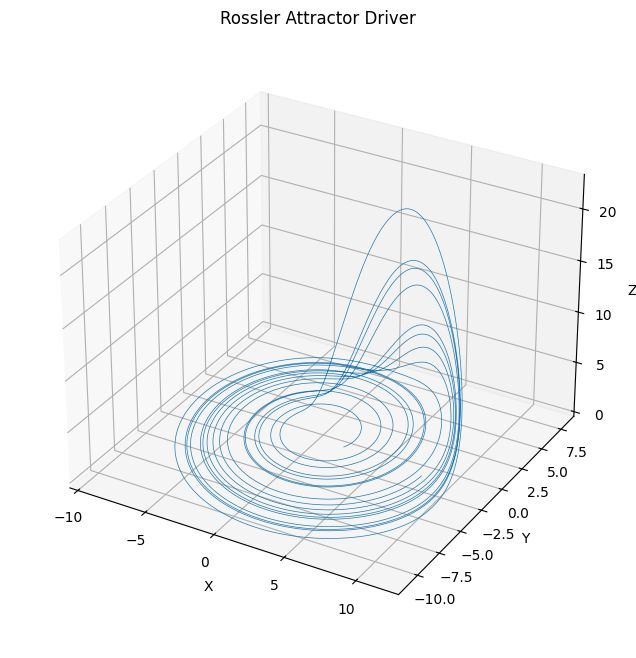

In [12]:
t_max = 100
t = np.linspace(0, t_max, 10000)

ic = [1, 1, 1]   # initial condition

# given parameters
a = 0.2
b = 0.2
c = 5.7

# solve system
driver_solution = solve_ivp(rossler_driver, (0,t_max), ic, args=(a, b, c), t_eval=t)

# remove first 500 solutions from driver_solution
driver_solution.y = driver_solution.y[:, 500:]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# coordinates to plot
x, y, z = driver_solution.y

# plot result
ax.plot3D(x, y, z, lw=0.5)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title(r"Rossler Attractor Driver")
ax.set_box_aspect(None, zoom=0.95) # so we can see the z-axis label
plt.show()

## Part d

In [4]:
# reparamaterized system with controls
#   u1 = -2y
#   u2 = -ay
#   u3 = -(1+z_R)x + x_Dz
def driver_response_system(t, state, c):
  x, y, z = state

  x_d_dot = - y + z
  y_d_dot = x
  z_d_dot = -c * z - x

  return [x_d_dot, y_d_dot, z_d_dot]

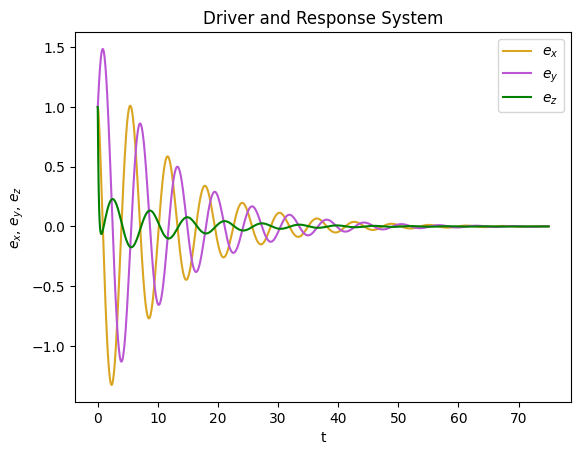

In [38]:
t_max = 75
t = np.linspace(0, t_max, 1000)

# solve system
# use same t, c, and initial condition from previous
driver_response_solution = solve_ivp(driver_response_system, (0,t_max), ic,
                                     args=(c,), t_eval=t)

# coordinates to plot
x, y, z = driver_response_solution.y

# plot result
plt.plot(t, x, label = r'$e_x$', color = 'goldenrod')
plt.plot(t, y, label = r'$e_y$', color = 'mediumorchid')
plt.plot(t, z, label = r'$e_z$', color = 'green')
plt.legend()
plt.xlabel('t')
plt.ylabel(r'$e_x$, $e_y$, $e_z$')
plt.title(r"Driver and Response System")
plt.show()